In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.metrics import silhouette_score   # ONLY for evaluation

# ====================== LOAD DATA ======================
data = pd.read_csv("../data/clustering_dataset.csv")
x = data.values
# scale features using standard scaler (mean=0, std=1) using sklearn import it 
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X = scaler.fit_transform(x)


# ====================== FROM-SCRATCH K-MEANS ======================
def compute_distances(X, centroids):
    return np.sqrt(np.sum((X[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2, axis=2))

def initialize_kmeans_plus_plus(X, k, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    n_samples = X.shape[0]
    centroids = [X[np.random.randint(n_samples)]]
    for _ in range(1, k):
        distances = compute_distances(X, np.array(centroids))
        min_dist = np.min(distances, axis=1)
        probs = min_dist ** 2
        probs /= probs.sum()
        next_idx = np.random.choice(n_samples, p=probs)
        centroids.append(X[next_idx])
    return np.array(centroids)

def assign_clusters(X, centroids):
    return np.argmin(compute_distances(X, centroids), axis=1)

def update_centroids(X, labels, k):
    new_centroids = np.zeros((k, X.shape[1]))
    for i in range(k):
        cluster_points = X[labels == i]
        new_centroids[i] = X[np.random.randint(0, X.shape[0])] if len(cluster_points) == 0 else cluster_points.mean(axis=0)
    return new_centroids

def compute_inertia(X, centroids, labels):
    inertia = 0.0
    for i in range(centroids.shape[0]):
        inertia += np.sum((X[labels == i] - centroids[i]) ** 2)
    return inertia

def kmeans(X, k, max_iters=100, tol=1e-4, init="kmeans++", random_state=None, verbose=False):
    if init == "random":
        centroids = X[np.random.choice(X.shape[0], k, replace=False)]
    else:
        centroids = initialize_kmeans_plus_plus(X, k, random_state)
    
    inertia_history = []
    for iteration in range(max_iters):
        labels = assign_clusters(X, centroids)
        new_centroids = update_centroids(X, labels, k)
        inertia = compute_inertia(X, new_centroids, labels)
        inertia_history.append(inertia)
        
        if verbose:
            print(f"   Iter {iteration:2d} → inertia = {inertia:10.4f}")
        
        if np.linalg.norm(new_centroids - centroids) < tol:
            if verbose:
                print(f"   → Converged at iteration {iteration}")
            break
        centroids = new_centroids
    
    return centroids, labels, inertia, inertia_history

In [2]:
print("🚀 Running K-Means for k = 1 to 10...\n")

metrics_list = []
optimal_k = 5          
best_sil = -np.inf

for k in range(1, 11):
    print(f"{'='*70}")
    print(f"🔹 Evaluating n_clusters = {k}")
    start = time.time()
    
    # verbose=False → NO per-iteration spam
    # Only the FINAL (last) inertia is returned and logged
    _, labels, final_inertia, inertia_history = kmeans(
        X, k=k, init="kmeans++", random_state=42, verbose=False
    )
    
    run_time = time.time() - start
    sil = silhouette_score(X, labels) if k > 1 else -1.0
    
    # Log ONLY the last iteration metrics
    print(f" Final inertia (last iteration) = {final_inertia:10.4f}")
    print(f" Silhouette                    = {sil:.4f}")
    print(f" Run time                      = {run_time:.4f} s")
    print(f"   (Converged in {len(inertia_history)} iterations)")
    print(f"{'='*70}\n")
    
    metrics_list.append({
        "model": "kmeans",
        "n_clusters": k,
        "epsilon": "",
        "min_pts": "",
        "inertia": round(final_inertia, 4),
        "silhouette": round(sil, 4),
        "n_noise": 0,
        "run_time": round(run_time, 4)
    })
    
    if sil > best_sil:
        best_sil = sil
        optimal_k = k

print(f"🏆 OPTIMAL k = {optimal_k} (highest silhouette = {best_sil:.4f})")

🚀 Running K-Means for k = 1 to 10...

🔹 Evaluating n_clusters = 1
 Final inertia (last iteration) = 20000.0000
 Silhouette                    = -1.0000
 Run time                      = 0.0090 s
   (Converged in 2 iterations)

🔹 Evaluating n_clusters = 2
 Final inertia (last iteration) = 12626.9580
 Silhouette                    = 0.3471
 Run time                      = 0.1075 s
   (Converged in 20 iterations)

🔹 Evaluating n_clusters = 3
 Final inertia (last iteration) =  6946.5642
 Silhouette                    = 0.4297
 Run time                      = 0.0937 s
   (Converged in 13 iterations)

🔹 Evaluating n_clusters = 4
 Final inertia (last iteration) =  4638.6777
 Silhouette                    = 0.4361
 Run time                      = 0.1050 s
   (Converged in 16 iterations)

🔹 Evaluating n_clusters = 5
 Final inertia (last iteration) =  3837.7644
 Silhouette                    = 0.4155
 Run time                      = 0.1389 s
   (Converged in 16 iterations)

🔹 Evaluating n_cluster


🎨 Generating plots for optimal k = 4...



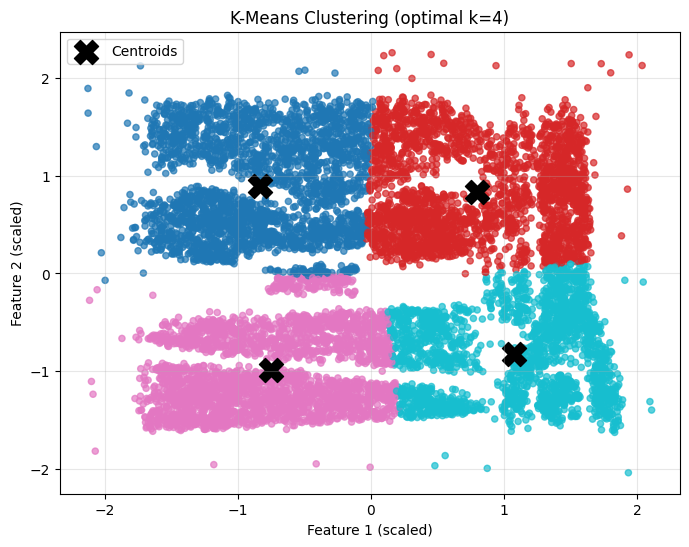

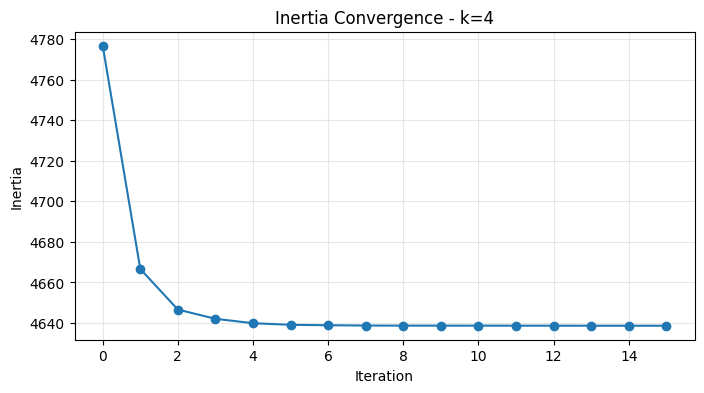

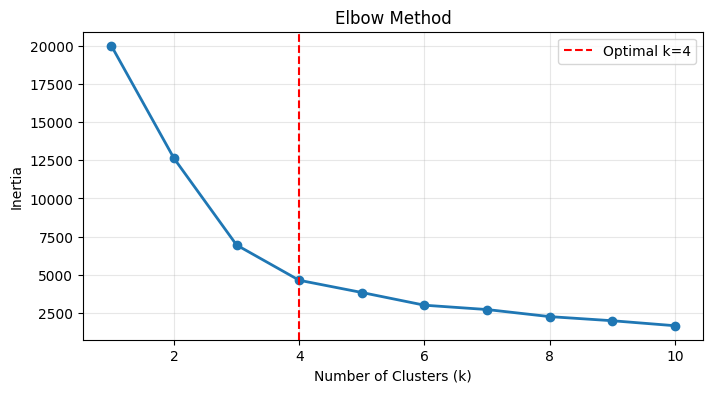

In [3]:
print(f"\n🎨 Generating plots for optimal k = {optimal_k}...\n")

# Re-run optimal model (clean run)
centroids, labels, final_inertia, inertia_history = kmeans(
    X, k=optimal_k, init="kmeans++", random_state=42, verbose=False
)

# 1. Cluster Scatter Plot
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='tab10', s=20, alpha=0.7)
plt.scatter(centroids[:, 0], centroids[:, 1], c='black', marker='X', s=300, label='Centroids')
plt.title(f'K-Means Clustering (optimal k={optimal_k})')
plt.xlabel('Feature 1 (scaled)')
plt.ylabel('Feature 2 (scaled)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 2. Inertia Convergence (per iteration for optimal k)
plt.figure(figsize=(8, 4))
plt.plot(inertia_history, marker='o')
plt.title(f'Inertia Convergence - k={optimal_k}')
plt.xlabel('Iteration')
plt.ylabel('Inertia')
plt.grid(alpha=0.3)
plt.show()

# 3. Elbow Plot (all k)
k_values = [m['n_clusters'] for m in metrics_list]
inertias = [m['inertia'] for m in metrics_list]
plt.figure(figsize=(8, 4))
plt.plot(k_values, inertias, marker='o', linewidth=2)
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.grid(alpha=0.3)
plt.axvline(x=optimal_k, color='red', linestyle='--', label=f'Optimal k={optimal_k}')
plt.legend()
plt.show()

In [4]:
# Create single row for optimal k only
optimal_row = pd.DataFrame([{
    "model": "kmeans",
    "n_clusters": optimal_k,
    "epsilon": "",
    "min_pts": "",
    "inertia": round(final_inertia, 4),
    "silhouette": round(best_sil, 4),
    "n_noise": 0,
    "run_time": round(metrics_list[optimal_k-1]['run_time'], 4)   # from earlier loop
}])

# Save
file_path = "../results.csv"
optimal_row.to_csv(file_path, index=False)

print("✅ SAVED to ../results.csv (only optimal row):")
print(optimal_row.to_string(index=False))

✅ SAVED to ../results.csv (only optimal row):
 model  n_clusters epsilon min_pts   inertia  silhouette  n_noise  run_time
kmeans           4                 4638.6777      0.4361        0     0.105
